# 如何基于 EM 确定 jieba 字典词频

## 摘要

[`fxsjy/jieba`][jieba]（及其在其它语言的 port）是一个简单[快速][jieba-rs]且[颇具教育意义][#957]的中文分词实现。由于其轻量快速的特点，我将其用于 [`kkew3/jieba.vim`][jieba.vim] 的后端。

在 `fxsjy/jieba` 使用者社区中的一个常见问题是<span style="color:green"><strong>如何追加自定义字典到 jieba 的默认字典并调整词频</strong></span>（例如 [#24]、[#482]、[#508]、[#555]、[#559] 等），这同样是 `kkew3/jieba.vim` 使用者的常见问题。注意该问题不同于[新词发现][5044-post]，而是给定字典如何确定每个词的词频。本笔记展示了一种快速、简单且兼容 `fxsjy/jieba` 分词机制的词频估计方法，希望能为这一问题提供一种思路。

[jieba]: https://github.com/fxsjy/jieba
[jieba-rs]: https://github.com/messense/jieba-rs
[jieba.vim]: https://github.com/kkew3/jieba.vim
[#957]: https://github.com/fxsjy/jieba/issues/957
[#24]: https://github.com/fxsjy/jieba/issues/24
[#482]: https://github.com/fxsjy/jieba/issues/482
[#508]: https://github.com/fxsjy/jieba/issues/508
[#555]: https://github.com/fxsjy/jieba/issues/555
[#559]: https://github.com/fxsjy/jieba/issues/559
[5044-post]: https://matrix67.com/blog/archives/5044


## 记号

- 带衬线粗体字：一个句子（例如 $\mathbf{x}$），同时使用同样符号带下标的普通字体表示单个字符（例如 $x_i$ 表示句子 $\mathbf{x}$ 的第 $i$ 个字符）。
- 冒号下标：包含两端的范围（例如 $\mathbf{x}_{i:j}$ 表示字符序列 $\langle x_i, x_{i+1}, \dots, x_j\rangle$）；注意 $\mathbf{x}_{i:i}$ 是序列 $\langle x_i\rangle$，在类型上不等同于 $x_i$。
- 字典 $D$ 表示字符序列/单词的集合。
- 文档集 $C$ 表示句子的集合，其中句子由若干字符序列拼接而成。


## jieba 分词基本原理

摘自 [`fxsjy/jieba` README][jieba-readme-algo]：

> - 基于前缀词典实现高效的词图扫描，生成句子中汉字所有可能成词情况所构成的有向无环图 (DAG)
> - 采用了动态规划查找最大概率路径, 找出基于词频的最大切分组合
> - 对于未登录词，采用了基于汉字成词能力的 HMM 模型，使用了 Viterbi 算法

我们的目的是确定字典的词频，因此主要关注 DAG 和查找最大概率路径这两步，无须关心对未登录词（OOV）的 HMM 处理。

首先看 jieba 的最新 Git 提交 [`67fa2e3`][jieba-commit] 是如何生成 DAG 的：

```python
def get_DAG(self, sentence):
    self.check_initialized()
    DAG = {}
    N = len(sentence)
    for k in xrange(N):
        tmplist = []
        i = k
        frag = sentence[k]
        while i < N and frag in self.FREQ:
            if self.FREQ[frag]:
                tmplist.append(i)
            i += 1
            frag = sentence[k:i + 1]
        if not tmplist:
            tmplist.append(k)
        DAG[k] = tmplist
    return DAG
```

总结一下，对于一个长度为 $N$ 的句子 $\mathbf{x}$，生成的 DAG 可写作 $G = (V, E)$。其中 $V = \{1, \dots, N\}$ 为节点集，对应这句话的每一个字符。$E$ 为边集。如果 $\mathbf{x}_{i:j}$（$j \ge i$）构成 $D$ 中的一个单词，其中下标 $i:j$ 表示一个闭区间，那么 $(i, j) \in E$；同时如果 $\forall j \ge i, \mathbf{x}_{i:j} \not\in D$，那么 $(i, i) \in E$（OOV 字符），从而保证 DAG 的连通性。

然后考虑查找最大概率路径的动态规划（DP）方法。jieba 代码如下：

```python
def calc(self, sentence, DAG, route):
    N = len(sentence)
    route[N] = (0, 0)
    logtotal = log(self.total)
    for idx in xrange(N - 1, -1, -1):
        route[idx] = max((log(self.FREQ.get(sentence[idx:x + 1]) or 1) -
                          logtotal + route[x + 1][0], x) for x in DAG[idx])
```

由上可知，DAG 的每条边要不对应一个字典中的单词，要不对应一个 OOV 字符。对于第一种情况，我们可以查询到该字典单词的归一化后的对数概率 $\log P(w) = \log(f_w / Z)$, $f_w$ 为 单词 $w$ 的 "频率", $Z = \sum_v f_v$；对于任意 OOV 字符 $u$，我们以一个特殊分数 $\log \tilde{P}(u) \equiv \log(1 / Z)$ 兜底。注意到，如果 DAG 中不存在 OOV 字符，那么从源节点 $1$ 到目标节点 $N$ 的最长路径所遍历的边构成一个基于词频的最优分词，且该最长路径的 "距离" 为最优分词的 unigram 对数似然的一个近似（详见 `doc/derivation.pdf` 中的推导）。由于 DAG 节点的拓扑排序已知，我们可以用如 `calc()` 函数所示的 DP 方法高效得到最长路径对应的得分最高的分词方案。

[jieba-readme-algo]: https://github.com/fxsjy/jieba/blob/master/README.md#算法
[jieba-commit]: https://github.com/fxsjy/jieba/commit/67fa2e36e72f69d9134b8a1037b83fbb070b9775


## 词频与 EM

由上所示，jieba 字典词频不能按照字面意义上的 "频率" 去理解，例如它通常不是一个文档集中每个单词出现的次数。原因是这里存在一个“先有鸡还是先有蛋”的问题：只有先确定分词方案，才能统计各个词的出现次数；但要确定分词方案，又需要预先给定词频参数。若直接统计字典中各个词在原始文本里的出现次数，同一段文本可能同时被计入多个重叠词语，因而无法直接得到与最终分词结果一致的词频。这是一个典型的隐变量推断问题，其中分词方案是隐变量，然后词频为可观测变量。自然地，我们可以使用期望最大化 (EM) 算法求解。


# 演示计划

在这里，我们将在 jieba 默认字典的基础上补充 [`iDvel/rime-ice`][rime-ice] 的基础字表 `8105.dict.yaml` 和基础词表 `base.dict.yaml`。

我们需要至少 140 GB 的可利用磁盘空间。其中占大头的文件是：

- 维基百科中文：12 GB
- DAG 缓存：125 GB

建议使用 NVMe SSD 以保证训练可以在合理的时间内完成。

我们将使用 [`uv`][uv] 管理依赖并运行脚本。

[rime-ice]: https://github.com/iDvel/rime-ice
[uv]: https://docs.astral.sh/uv/


## 演示路线图

本实验分为三个阶段：

1. 建立基线：比较直接统计词频、合并现有词典以及仅使用 jieba 默认词典的分词效果。
2. 加速训练：预先构建并缓存语料的 DAG，避免在每轮 EM 迭代中重复执行词语匹配。
3. 训练与评估：利用 Dirichlet 先验进行 EM 训练，并通过验证集选择超参数，最后比较训练前后的分词效果。


## 准备工作

### 安装依赖

首先保证所有依赖都已安装：

In [1]:
!uv sync --locked

Resolved 154 packages in 2.52s
Checked 150 packages in 18ms


### 下载字典

为保证可复现我们指定了 commit hash。

In [2]:
!mkdir -p train_dicts
!test -d train_dicts/jieba || ( git clone https://github.com/fxsjy/jieba.git train_dicts/jieba && cd train_dicts/jieba && git checkout 67fa2e3; )
!test -d train_dicts/rime-ice || ( git clone https://github.com/iDvel/rime-ice.git train_dicts/rime-ice && cd train_dicts/rime-ice && git checkout 75e6572; )
!ls -dF train_dicts/{jieba,rime-ice}

train_dicts/jieba/  train_dicts/rime-ice/


生成 `vocab` 词典文件：

In [3]:
VOCAB_FILE = "train_dicts/jieba_rime_base.vocab"

In [4]:
from jieba_em_train import load_dict
from jieba_em_train.vocab import Vocab

V = load_dict.load_jieba_dict("train_dicts/jieba/jieba/dict.txt")
# `mark_as_main=False`: 标记 Rime 词表为附属字典，用于在后续 EM 训练中指定先验
load_dict.load_rime_dict_into_vocab(V, "train_dicts/rime-ice/cn_dicts/8105.dict.yaml", mark_as_main=False)
load_dict.load_rime_dict_into_vocab(V, "train_dicts/rime-ice/cn_dicts/base.dict.yaml", mark_as_main=False)
V.dump(VOCAB_FILE, jieba_compatible=False)

!wc -cl $VOCAB_FILE | numfmt --to=si --field=-2

    706K      12M train_dicts/jieba_rime_base.vocab


### 下载维基中文数据集

首先设置 `TRAIN_TXT` 到希望的文件路径，需要保证该路径所在的磁盘有至少 30 GB 的可利用空间。

In [5]:
TRAIN_TXT = "/scratch/jieba-em-train/train_wiki.txt"

如果数据集不存在、或其校验和不匹配，下载数据集：

In [6]:
!echo "dd5cc6e56d872338  $TRAIN_TXT" | b2sum -l 64 -c || uv run --no-sync process-wiki-data $TRAIN_TXT

/scratch/jieba-em-train/train_wiki.txt: OK


### 下载 MSRA Bakeoff 分词数据集

我们主要使用这个数据集作为验证/测试集来评估训练效果。

首先设置目标文件夹 `MSRA_BACKEOFF_DIR`：

In [7]:
MSRA_BACKEOFF_DIR = "/scratch/jieba-em-train"
VAL_XML = f"{MSRA_BACKEOFF_DIR}/msra_bakeoff3_training.xml"
TEST_XML = f"{MSRA_BACKEOFF_DIR}/msra_bakeoff3_test.xml"

数据集 zip 压缩包可在这个地址下载到：<https://www.microsoft.com/en-sg/download/details.aspx?id=52531>。下载完成后把压缩包里面的两个 xml 文件解压到 `MSRA_BACKEOFF_DIR`。

验证下载到的文件是否正确：

In [8]:
!echo "cba765c5cf023a0e  $VAL_XML" | b2sum -l 64 -c
!echo "b6e5850d181fb9a2  $TEST_XML" | b2sum -l 64 -c

/scratch/jieba-em-train/msra_bakeoff3_training.xml: OK
/scratch/jieba-em-train/msra_bakeoff3_test.xml: OK


将 xml 转为纯文本以便后续处理：

In [9]:
VAL_TXT = f"{MSRA_BACKEOFF_DIR}/msra_bakeoff3_training.txt"
TEST_TXT = f"{MSRA_BACKEOFF_DIR}/msra_bakeoff3_test.txt"

!uv run --no-sync parse-msra-xml $VAL_XML $VAL_TXT
!uv run --no-sync parse-msra-xml $TEST_XML $TEST_TXT

## 基线 1：Naive 词频估计

容易注意到 naive 词频估计，即直接统计维基中文数据集里字典中每个单词出现的频率，尽管是一个合理的基线，通常不会导致很好的分词结果。这里我们使用 Aho-Corasick 算法快速找出所有单词实例。

In [10]:
import numpy as np
import ahocorasick

from jieba_em_train.vocab import Vocab
from jieba_em_train import preprocess_data, eval_jieba

V = Vocab.load(VOCAB_FILE, jieba_compatible=False)
aho = ahocorasick.Automaton()
for word in V:
    aho.add_word(word, V[word])
aho.make_automaton()
word_freqs = np.zeros(len(V), dtype=int)
with open(TRAIN_TXT, encoding="utf-8") as infile:
    for sent in preprocess_data.iter_sentences(infile, ascii=True, mininterval=5):
        for _, v_idx in aho.iter(sent):
            word_freqs[v_idx] += 1
for word_idx, freq in enumerate(word_freqs.tolist()):
    V.update_freq(word_idx, freq)
jb = eval_jieba.configure_jieba(V)

100%|###################################################################################| 432379577/432379577 [1:15:13<00:00, 95806.22it/s]


字典单词的对数概率分布（$-\infty$ 所处的 bin 绘制于 -30 的位置）：

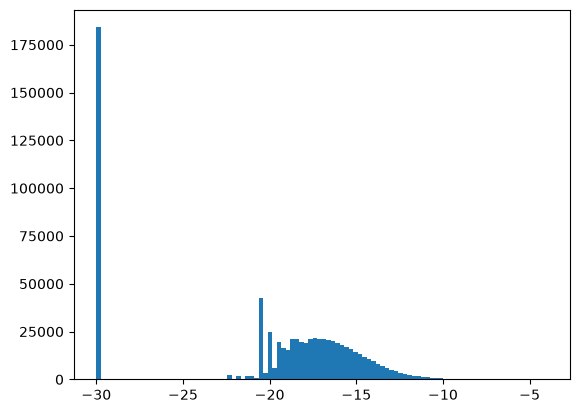

In [11]:
from matplotlib import pyplot as plt

def plot_logprob(v: Vocab):
    lp = V.as_logprob_array()
    plt.hist(np.where(np.isinf(lp), -30, lp), bins=100)

plot_logprob(V)

测试集 $F_1$ 分数：

In [12]:
eval_jieba.Fbeta(*eval_jieba.count_pred_stats(0, 0, 0, jb, eval_jieba.iter_segmented_sentences(TEST_TXT))).get()

0.8751203505393669

分词示例：

In [13]:
print(eval_jieba.pprint_cut(jb.cut("""\
自然语言处理是人工智能领域的重要分支。近年来，随着深度学习技术的飞速发展，中文分词算法取得了显著进步。
结巴分词作为一款优秀的开源工具，因其高效、准确且易于使用的特点，受到了广大开发者的广泛青睐。它支持多种分词模式，能够完美满足不同场景下的文本处理需求。
佐佐木小次郎曾与宫本武藏在岩流岛上展开著名的决斗。""")))

自然/语言/处理/是/人/工智能/领域/的/重要/分支/。/近年/来/，/随着/深度/学习/技术/的/飞速/发展/，/中文分/词算法/取得/了/显著/进步/。
结巴分/词作/为/一款/优秀/的/开源/工具/，/因其/高效/、/准确/且/易于/使/用/的/特点/，/受到/了/广大开/发者/的/广泛/青睐/。/它/支持/多种/分词/模式/，/能够/完美/满足/不/同场/景下/的/文本/处理/需求/。
佐佐木小次/郎/曾/与/宫本/武藏/在/岩流岛/上展/开著名/的/决斗/。


## 准备工作 2：DAG 缓存

在上面的 naive 词频实验中，我们发现 Aho-Corasick 词语搜索占据了大量的时间（一个小时）。为了使之后的后验词频统计（EM 算法的 E 步）能在合理的时间完成，我们事先使用 Aho-Corasick 得到数据集句子的 DAG 并缓存于文件中，之后训练时只需顺序读取 DAG 文件即可。DAG 文件的格式记录于 `src/jieba_em_train/build_dag.py`。

设置 `DAG_NAME` 为希望的文件路径，需要确保路径所在磁盘有至少 125 GB 的可利用空间，磁盘最好是 NVMe SSD，以保证足够的顺序读取速度。

In [14]:
DAG_NAME = "/scratch/jieba-em-train/train_rime_base"

In [15]:
!echo "fb2cee5b87d9700f *{DAG_NAME}.dag.offset" | b2sum -l 64 -c && echo "3c83f4f5573dfad1 *{DAG_NAME}.dag" | b2sum -l 64 -c \
    || uv run --no-sync build-dag $VOCAB_FILE $TRAIN_TXT $DAG_NAME

/scratch/jieba-em-train/train_rime_base.dag.offset: OK
/scratch/jieba-em-train/train_rime_base.dag: OK


## 基线 2：直接使用 jieba 默认字典词频和 rime-ice 词频的并集进行分词

In [16]:
from jieba_em_train.vocab import Vocab
from jieba_em_train import eval_jieba

V = Vocab.load(VOCAB_FILE, jieba_compatible=False)
jb = eval_jieba.configure_jieba(V)

字典单词的对数概率分布（$-\infty$ 所处的 bin 绘制于 -30 的位置）：

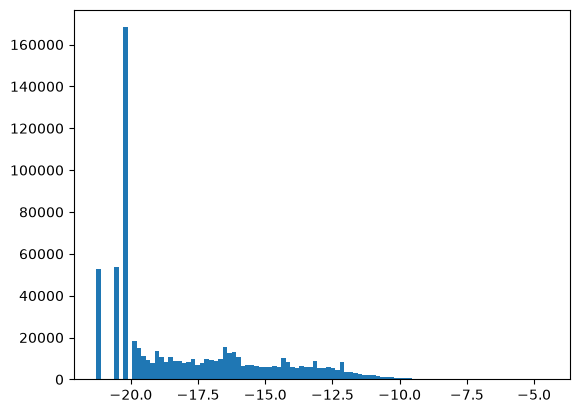

In [17]:
plot_logprob(V)

测试集 $F_1$ 分数：

In [18]:
eval_jieba.Fbeta(*eval_jieba.count_pred_stats(0, 0, 0, jb, eval_jieba.iter_segmented_sentences(TEST_TXT))).get()

0.8751203505393669

分词示例：

In [19]:
print(eval_jieba.pprint_cut(jb.cut("""\
自然语言处理是人工智能领域的重要分支。近年来，随着深度学习技术的飞速发展，中文分词算法取得了显著进步。
结巴分词作为一款优秀的开源工具，因其高效、准确且易于使用的特点，受到了广大开发者的广泛青睐。它支持多种分词模式，能够完美满足不同场景下的文本处理需求。
佐佐木小次郎曾与宫本武藏在岩流岛上展开著名的决斗。""")))

自然/语言/处理/是/人/工智能/领域/的/重要/分支/。/近年/来/，/随着/深度/学习/技术/的/飞速/发展/，/中文分/词算法/取得/了/显著/进步/。
结巴分/词作/为/一款/优秀/的/开源/工具/，/因其/高效/、/准确/且/易于/使/用/的/特点/，/受到/了/广大开/发者/的/广泛/青睐/。/它/支持/多种/分词/模式/，/能够/完美/满足/不/同场/景下/的/文本/处理/需求/。
佐佐木小次/郎/曾/与/宫本/武藏/在/岩流岛/上展/开著名/的/决斗/。


## 基线 3：jieba 默认字典

In [20]:
import rjieba

from jieba_em_train import eval_jieba

jb = rjieba.Jieba()

测试集 $F_1$ 分数（好像 `jieba` 的默认词频就是在这个人民日报数据集上训练的，所以这个分数不是很具参考意义）：

In [21]:
eval_jieba.Fbeta(*eval_jieba.count_pred_stats(0, 0, 0, jb, eval_jieba.iter_segmented_sentences(TEST_TXT))).get()

0.929047234557933

分词示例：

In [22]:
print(eval_jieba.pprint_cut(jb.cut("""\
自然语言处理是人工智能领域的重要分支。近年来，随着深度学习技术的飞速发展，中文分词算法取得了显著进步。
结巴分词作为一款优秀的开源工具，因其高效、准确且易于使用的特点，受到了广大开发者的广泛青睐。它支持多种分词模式，能够完美满足不同场景下的文本处理需求。
佐佐木小次郎曾与宫本武藏在岩流岛上展开著名的决斗。""")))

自然语言/处理/是/人工智能/领域/的/重要/分支/。/近年来/，/随着/深度/学习/技术/的/飞速发展/，/中文/分词/算法/取得/了/显著/进步/。
结巴/分词/作为/一款/优秀/的/开源/工具/，/因/其/高效/、/准确/且/易于/使用/的/特点/，/受到/了/广大/开发者/的/广泛/青睐/。/它/支持/多种/分/词模式/，/能够/完美/满足/不同/场景/下/的/文本处理/需求/。
佐佐木/小/次郎/曾/与/宫本/武/藏在岩/流/岛上/展开/著名/的/决斗/。


## EM 训练

每轮 EM 迭代包含以下两个步骤：

1. （E 步）统计以当前词频参数得到的分词后验下的词频，即考虑所有可能的切分方案，并计算各个词在切分后验分布下的期望出现次数；
2. （M 步）结合 E 步得到的期望词频与 Dirichlet 先验，更新词频参数。

重复上述过程，直到满足停止条件，例如达到预设迭代次数、参数变化足够小，或验证集上的 $F_1$ 分数不再提升。

我们将使用 rust 编写的原生后验词频统计程序训练。rust 源代码见 `src/lib.rs`，先验分布和训练循环代码见 `src/jieba_em_train/em_training.py`。

### Dirichlet 先验

由于 jieba 近似使用的 unigram 语言模型（详见 `doc/derivation.pdf` 的推导）的似然遵循 Multinomial 分布，我们可以使用与其共轭的 Dirichlet 分布施加先验。因为我们的目的是给定词频的 jieba 默认字典和给定词频（例如来自 rime-ice）的自定义字典，在此基础上调整词频得到最佳分词效果，所以可以设置先验为 jieba 默认字典的初始词频和 rime-ice 的初始词频。

### 调整超参数

我们可以使用 [`optuna`][optuna] 自动寻找最优超参数（例如先验强度），使用例子见 `examples/train_extended_dict.py`。在此稍作讲解：例子代码中使用

```python
return (
    0.125 * est.score(TEST_PATH)
    + 0.25 * ("左执法" in est.predict("宫本武藏担任左执法"))
    + 0.5 * ("开发者" in est.predict("受到了广大开发者的广泛青睐"))
    + 1 * (est.best_f1_ > 0.9)
)
```

作为超参数的分数。该分数由四项人工设计的指标加权组成，权重按照预期重要性递减排列：

1. 验证集上的最高分数必须大于 0.9；
2. "开发者"（而不是，例如，"开发/者"） 需要被分出来，其目的是确保训练后的词频仍能保留 jieba 默认字典在这一例句上的分词行为；
3. "左执法" 可以被分出来，这个的目的是希望 rime-ice 词表独有的单词可以被分出来；
4. 最后，在 `TEST_PATH` 上的 $F_1$ 分数越高越好。这里的 `TEST_PATH`（不同于上面的 MSRA 测试集）是我自己整理的 65 个分好词的句子，没有公开，仅用作 sanity check。

需要说明的是，以上人工设计的评分项属于针对特定分词行为的启发式约束，并不等同于通用的分词质量指标；因此，最终效果仍应通过未参与超参数选择的独立测试集评估。这四个标准并不完美，不过从实际训练来看对超参数的寻找还是存在一定的指导意义。

为避免重复运行耗时较长的超参数搜索，下面直接使用此前搜索得到的最佳超参数进行演示。

[optuna]: https://optuna.readthedocs.io/en/stable/

In [23]:
import numpy as np

from jieba_em_train import em_training, eval_jieba

V = Vocab.load(VOCAB_FILE, jieba_compatible=False)
prior = em_training.MainSubsetPrior(mix_prior=1794506 * np.array([0.367539, 1 - 0.367539]), kappa_main=22209328.92, kappa_non_main=50)
_, (log_theta, _, _) = em_training.train_loops(
    V, prior, tau=0.6826, n_iter=6,
    dag_name=DAG_NAME,
    val_msra_path=VAL_TXT,
    n_jobs=4,
)

[2026-10-26T00:02:35.290319] ITER -1 F1: 0.85285111955393
[2026-10-26T00:20:41.490534] ITER 0 F1: 0.8966749116430708
[2026-10-26T00:31:00.786307] ITER 1 F1: 0.9032686804159387
[2026-10-26T00:38:04.050164] ITER 2 F1: 0.9040979057833912
[2026-10-26T00:43:49.111922] ITER 3 F1: 0.9042591795960118
[2026-10-26T00:52:38.120023] ITER 4 F1: 0.9043839979201196
[2026-10-26T00:58:22.431423] ITER 5 F1: 0.9043901745242333
Best iter: 5 at F1: 0.9043901745242333


字典单词的对数概率分布（$-\infty$ 所处的 bin 绘制于 -30 的位置）：

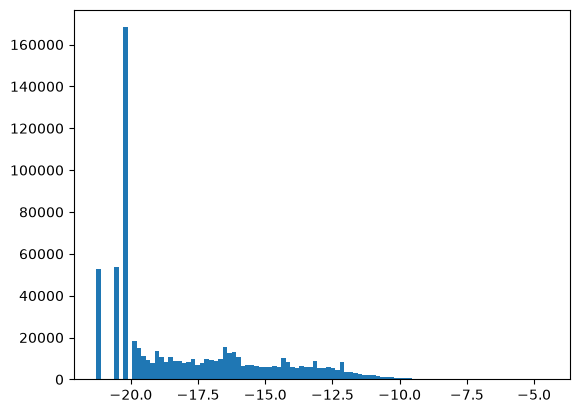

In [24]:
plot_logprob(eval_jieba.export_vocab(V, log_theta))

测试集 $F_1$ 分数：

In [25]:
jb = eval_jieba.configure_jieba(V, log_theta)
eval_jieba.Fbeta(*eval_jieba.count_pred_stats(0, 0, 0, jb, eval_jieba.iter_segmented_sentences(TEST_TXT))).get()

0.9146472129231369

分词示例：

In [26]:
print(eval_jieba.pprint_cut(jb.cut("""\
自然语言处理是人工智能领域的重要分支。近年来，随着深度学习技术的飞速发展，中文分词算法取得了显著进步。
结巴分词作为一款优秀的开源工具，因其高效、准确且易于使用的特点，受到了广大开发者的广泛青睐。它支持多种分词模式，能够完美满足不同场景下的文本处理需求。
佐佐木小次郎曾与宫本武藏在岩流岛上展开著名的决斗。""")))

自然语言/处理/是/人工智能/领域/的/重要/分支/。/近年来/，/随着/深度/学习/技术/的/飞速发展/，/中文/分词/算法/取得了/显著/进步/。
结巴/分词/作为/一款/优秀/的/开源/工具/，/因其/高效/、/准确/且/易于/使用的/特点/，/受到了/广大/开发者/的/广泛/青睐/。/它/支持/多种/分词/模式/，/能够/完美/满足/不同/场景/下的/文本处理/需求/。
佐佐木小次郎/曾与/宫本/武藏/在/岩流/岛上/展开/著名/的/决斗/。


# 结论

可见，虽然 EM 训练后的对数概率分布与基线 2 没有肉眼可见的差异，但正是这些细微调整提升了分词质量，这是因为分词结果由候选词之间的相对得分决定，少量词频的调整就可能改变某些位置上的最优切分路径；此外，训练后的词频使部分 jieba 默认字典中不存在的词能够以合理的方式参与分词，说明该方法不仅可以调整已有词语的相对权重，也可以帮助扩展词典与默认词典协同工作。

上述结论应以实际的验证集和独立测试集指标为依据；对数概率分布图与个别分词示例主要用于辅助理解，而不能单独证明整体分词质量得到提升。

最后，以一个对比表格结束我们的演示：

| 方法 | 测试集 $F_1$ |
|---|---|
| Naive 词频估计 | 0.875 |
| 默认字典 + 自定义扩展字典 | 0.875 |
| 默认字典 | **0.929** (*) |
| 默认字典 + 自定义扩展字典（EM）| **0.915** |

(*)：可能因为测试集泄露导致